# 07 – Extensions: absolute numbers, response times and full-year context
Three additions to the main analysis (Notebooks 03–04):

1. **Absolute numbers.** How many more EMS missions do hot days have, in missions instead of index points?
2. **Response times.** Do ambulances take longer to arrive on hot days?
3. **Full-year context.** How does demand relate to temperature over the whole year, and is the focus on summer justified?
4. **Robustness.** Do public holidays change the main result?

All results are associations from observational data. "More missions on hot days" does not mean that heat caused each of them.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
import zipfile
from scipy import stats
from pathlib import Path

raw_folder = Path("../data/raw")
clean_folder = Path("../data/clean")
figures_folder = Path("../figures")
tableau_folder = Path("../tableau")

daily = pd.read_csv(clean_folder / "daily_summer.csv", parse_dates=["date"])
summer = daily[(daily["in_summer"] == 1) & daily["ems_missions"].notna()].copy()
summer = summer.sort_values("date")
print(summer.shape)

(822, 13)


In [2]:
# Same model set-up as Notebook 04: adjusted for year, month and weekday,
# with HAC standard errors that correct for streaks of similar days.
hac = {"cov_type": "HAC", "cov_kwds": {"maxlags": 7}}
controls = "C(year) + C(month) + C(weekday_num)"

def report(model, variable, label, unit):
    ci_low, ci_high = model.conf_int().loc[variable]
    print(f"{label}: {model.params[variable]:+.1f} {unit}, "
          f"95% CI [{ci_low:.1f}, {ci_high:.1f}], p = {model.pvalues[variable]:.1e}")

## 1. Absolute numbers
Notebook 04 reports the hot-day effect in index points (+7.1). The same model is run here on the raw mission counts, so the result reads directly as missions per day.

In [3]:
missions_hot = smf.ols(f"ems_missions ~ hot_day + {controls}", data=summer).fit(**hac)
missions_temp = smf.ols(f"ems_missions ~ tmax + {controls}", data=summer).fit(**hac)

report(missions_hot, "hot_day", "Hot day", "EMS missions")
report(missions_temp, "tmax", "Per +1°C", "EMS missions")

Hot day: +89.7 EMS missions, 95% CI [74.3, 105.1], p = 2.5e-30
Per +1°C: +10.8 EMS missions, 95% CI [9.0, 12.6], p = 1.7e-32


In [4]:
# What does this add up to per summer?
# Hot days are counted from the complete weather data (including the few days without mission data).
effect = missions_hot.params["hot_day"]
effect_low, effect_high = missions_hot.conf_int().loc["hot_day"]

hot_days = daily[daily["in_summer"] == 1].groupby("year")["hot_day"].sum()

per_summer = pd.DataFrame({"hot_days": hot_days})
per_summer["extra_missions"] = (per_summer["hot_days"] * effect).round(0).astype(int)
print(per_summer)

average_hot_days = hot_days.mean()
print(f"\nAverage summer: {average_hot_days:.1f} hot days × {effect:.0f} missions = about {round(average_hot_days * effect, -2):,.0f} more EMS missions on hot days "
      f"(range {round(average_hot_days * effect_low, -2):,.0f}–{round(average_hot_days * effect_high, -2):,.0f})")

      hot_days  extra_missions
year                          
2018        25            2243
2019        25            2243
2020        16            1435
2021        13            1166
2022        21            1884
2023        11             987
2024        14            1256
2025        11             987
2026        21            1884

Average summer: 17.4 hot days × 90 missions = about 1,600 more EMS missions on hot days (range 1,300–1,800)


The per-summer figures apply one average difference to every hot day. They are a rough estimate of scale, not a count of missions caused by heat.

## 2. Response times
The Fire Brigade publishes the daily **median response time for critical EMS missions**: the time from the creation of the mission until the first vehicle arrives, plus 2 minutes for the emergency call and dispatch. Values are in seconds.

The figures below are **averages of these daily medians**. They are not the median over all individual missions.

A plausible expectation: if hot days have more missions for the same number of ambulances, response times get longer.

In [5]:
raw_missions = pd.read_csv(raw_folder / "BFw_mission_data_daily.csv", parse_dates=["mission_created_date"])
raw_missions = raw_missions.rename(columns={
    "mission_created_date": "date",
    "response_time_ems_critical_median": "response_time",
    "mission_count_ems_critical": "critical_missions"
})

summer = summer.merge(raw_missions[["date", "response_time", "critical_missions"]], on="date", how="left", validate="one_to_one")

print("Missing response times:", summer["response_time"].isna().sum())
summer["response_time"].describe().round(1)

Missing response times: 0


count    822.0
mean     586.4
std       27.1
min      528.0
25%      566.1
50%      584.5
75%      605.0
max      677.5
Name: response_time, dtype: float64

In [6]:
print(summer.groupby("hot_day")["response_time"].agg(["count", "mean", "median"]).round(1))

rt_per_year = summer.groupby(["year", "hot_day"])["response_time"].mean().unstack().round(1)
rt_per_year.columns = ["normal_days", "hot_days"]
rt_per_year["difference"] = rt_per_year["hot_days"] - rt_per_year["normal_days"]
rt_per_year["hot_slower"] = rt_per_year["difference"] > 0
print()
print(rt_per_year)

k = rt_per_year["hot_slower"].sum()
n = len(rt_per_year)
p_sign = stats.binomtest(k, n, p=0.5, alternative="greater").pvalue
print(f"\nResponse times longer on hot days in {k} of {n} summers, sign test p = {p_sign:.4f}")

         count   mean  median
hot_day                      
0          667  583.8   581.0
1          155  597.9   597.0

      normal_days  hot_days  difference  hot_slower
year                                               
2018        565.6     584.5        18.9        True
2019        558.6     577.2        18.6        True
2020        571.0     594.2        23.2        True
2021        590.1     604.7        14.6        True
2022        618.3     643.4        25.1        True
2023        607.5     623.1        15.6        True
2024        599.5     612.0        12.5        True
2025        567.7     573.2         5.5        True
2026        569.7     580.7        11.0        True

Response times longer on hot days in 9 of 9 summers, sign test p = 0.0020


In [7]:
rt_hot = smf.ols(f"response_time ~ hot_day + {controls}", data=summer).fit(**hac)
rt_temp = smf.ols(f"response_time ~ tmax + {controls}", data=summer).fit(**hac)
rt_demand = smf.ols(f"response_time ~ ems_missions + {controls}", data=summer).fit(**hac)

report(rt_hot, "hot_day", "Hot day", "seconds")
report(rt_temp, "tmax", "Per +1°C", "seconds")
print(f"Per 100 more EMS missions: {rt_demand.params['ems_missions'] * 100:+.1f} seconds")

# Diagnostic: how much of the hot-day difference remains on days with the same number of missions?
rt_hot_given_demand = smf.ols(f"response_time ~ hot_day + ems_missions + {controls}", data=summer).fit(**hac)
report(rt_hot_given_demand, "hot_day", "Hot day, at the same number of missions", "seconds")

Hot day: +16.9 seconds, 95% CI [13.6, 20.1], p = 5.1e-24
Per +1°C: +1.6 seconds, 95% CI [1.3, 2.0], p = 1.2e-20
Per 100 more EMS missions: +12.5 seconds
Hot day, at the same number of missions: +7.0 seconds, 95% CI [3.7, 10.3], p = 3.5e-05


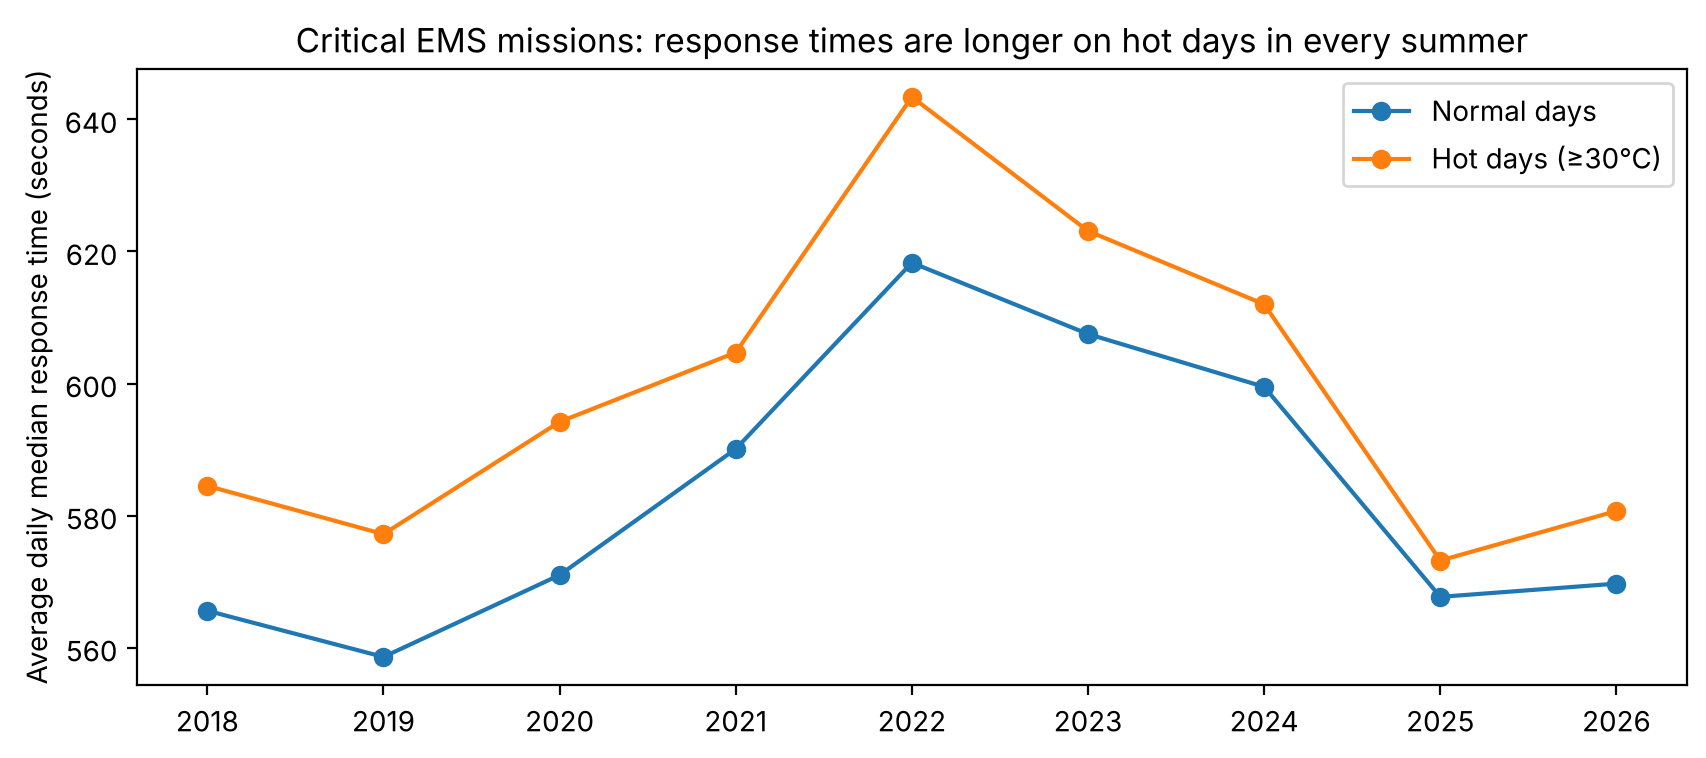

In [8]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(rt_per_year.index, rt_per_year["normal_days"], marker="o", color="tab:blue", label="Normal days")
ax.plot(rt_per_year.index, rt_per_year["hot_days"], marker="o", color="tab:orange", label="Hot days (≥30°C)")
ax.set_xticks(rt_per_year.index)
ax.set_ylabel("Average daily median response time (seconds)")
ax.set_title("Critical EMS missions: response times are longer on hot days in every summer")
ax.legend()

plt.savefig(figures_folder / "response_time_hot_vs_normal.png", dpi=150, bbox_inches="tight")
plt.show()

### Sensitivity: a change in the "critical" category
Response times are measured on critical missions only. The number of missions classified as critical drops sharply from 2025, which points to a change in how missions are categorised. The model is therefore re-run separately for the two periods.

In [9]:
print("Average critical EMS missions per summer day:")
print(summer.groupby("year")["critical_missions"].mean().round(0).astype(int).to_string())
print()

periods = {
    "All summers": summer,
    "2018–2024": summer[summer["year"] <= 2024],
    "2025–2026": summer[summer["year"] >= 2025],
}

for name, subset in periods.items():
    model = smf.ols(f"response_time ~ hot_day + {controls}", data=subset).fit(**hac)
    report(model, "hot_day", name, "seconds")

Average critical EMS missions per summer day:
year
2018    1015
2019    1068
2020    1006
2021    1103
2022    1216
2023    1179
2024    1269
2025     759
2026     731

All summers: +16.9 seconds, 95% CI [13.6, 20.1], p = 5.1e-24
2018–2024: +18.3 seconds, 95% CI [14.9, 21.8], p = 2.6e-25
2025–2026: +9.8 seconds, 95% CI [3.5, 16.0], p = 2.3e-03


## 3. Full-year context
The main analysis looks at June–August only. Here every day from January 2018 to November 2026 is used, to see how demand relates to temperature over the whole year.

Demand is expressed as an index relative to the average day of the **same calendar year** (100 = average day of that year). This is a different baseline from the summer index in Notebooks 03–05, so the two are not directly comparable.

This is a descriptive comparison. It is not adjusted for season, weekday or anything else, and 2026 only runs to early November.

In [10]:
def read_dwd_zip(zip_path):
    with zipfile.ZipFile(zip_path) as z:
        data_file = [name for name in z.namelist() if name.startswith("produkt_klima_tag")][0]
        with z.open(data_file) as f:
            df = pd.read_csv(f, sep=";", skipinitialspace=True)
    df.columns = df.columns.str.strip()
    return df

weather_hist = read_dwd_zip(raw_folder / "tageswerte_KL_00433_19480101_20251231_hist.zip")
weather_recent = read_dwd_zip(raw_folder / "tageswerte_KL_00433_akt.zip")

weather = pd.concat([weather_hist, weather_recent], ignore_index=True)
weather = weather.drop_duplicates(subset="MESS_DATUM", keep="first")
weather["date"] = pd.to_datetime(weather["MESS_DATUM"].astype(str), format="%Y%m%d")
weather["tmax"] = weather["TXK"].replace(-999, float("nan"))

full_year = raw_missions[["date", "mission_count_ems"]].merge(weather[["date", "tmax"]], on="date", how="left", validate="one_to_one")
full_year = full_year.rename(columns={"mission_count_ems": "ems_missions"})

# Same exclusion as in Notebook 02 (suspected reporting anomaly)
full_year = full_year[full_year["date"] != pd.Timestamp("2018-06-07")]

print(full_year.shape)
print("First day:", full_year["date"].min().date(), "| Last day:", full_year["date"].max().date())
print("Missing temperatures:", full_year["tmax"].isna().sum())

(3222, 3)
First day: 2018-01-01 | Last day: 2026-11-04
Missing temperatures: 0


In [11]:
full_year["year"] = full_year["date"].dt.year
full_year["ems_index_year"] = full_year["ems_missions"] / full_year.groupby("year")["ems_missions"].transform("mean") * 100

band_labels = ["<0", "0–5", "5–10", "10–15", "15–20", "20–25", "25–30", "30–34", "34+"]
# Top bands end at 34°C to match the summer temperature bands in Notebooks 03–05
full_year["temp_band"] = pd.cut(full_year["tmax"], bins=[-30, 0, 5, 10, 15, 20, 25, 30, 34, 50], right=False, labels=band_labels)

by_band = full_year.groupby("temp_band", observed=True)["ems_index_year"].agg(["count", "mean", "median"]).round(1)
by_band

,count,mean,median
temp_band,,,
<0,75,100.8,101.7
0–5,331,98.7,99.2
5–10,553,99.7,99.9
10–15,538,98.4,98.4
15–20,529,98.6,98.5
20–25,601,99.6,99.1
25–30,422,102.9,102.8
30–34,136,105.9,105.8
34+,37,109.2,106.8


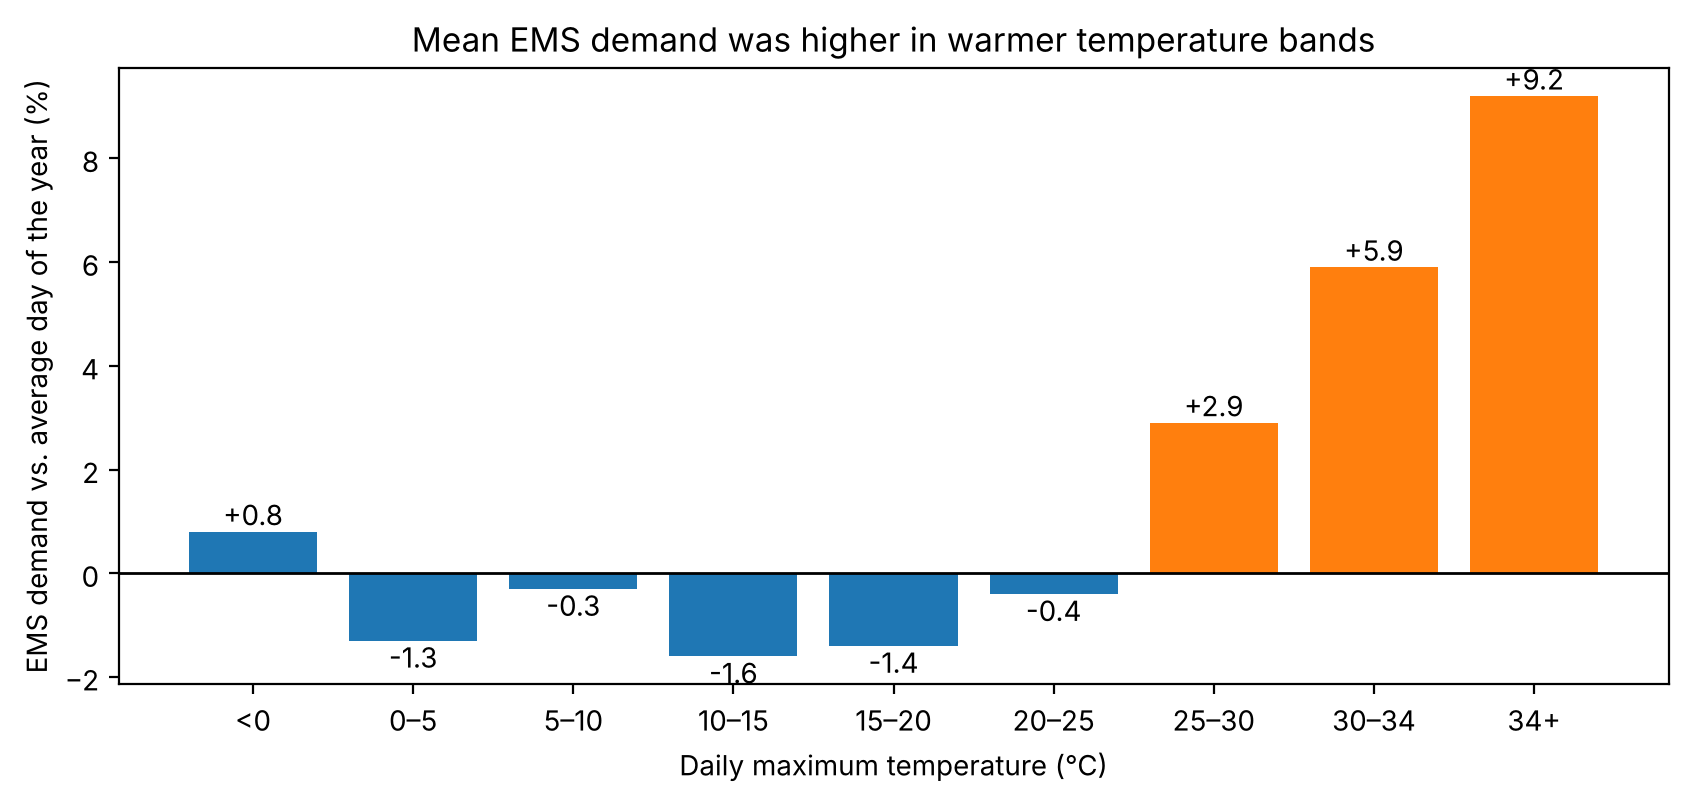

In [12]:
fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(by_band.index.astype(str), by_band["mean"] - 100, color=["tab:blue"] * 6 + ["tab:orange"] * 3)
ax.bar_label(bars, fmt="%+.1f")
ax.axhline(0, color="black", linewidth=1)
ax.set_xlabel("Daily maximum temperature (°C)")
ax.set_ylabel("EMS demand vs. average day of the year (%)")
ax.set_title("Mean EMS demand was higher in warmer temperature bands")

plt.savefig(figures_folder / "full_year_demand_by_temperature.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Robustness: public holidays
Notebook 04 adjusts for weekday, but a public holiday on a Monday may behave like a Sunday. The only public holiday that can fall in June–August in Berlin is Whit Monday (50 days after Easter Sunday). The main model from Notebook 04 is re-run with a holiday indicator.

In [13]:
from dateutil.easter import easter

whit_mondays = [pd.Timestamp(easter(year)) + pd.Timedelta(days=50) for year in range(2018, 2027)]
summer["public_holiday"] = summer["date"].isin(whit_mondays).astype(int)
summer["ems_index"] = summer["ems_missions"] / summer.groupby("year")["ems_missions"].transform("mean") * 100

print("Whit Mondays in the data:")
print(summer.loc[summer["public_holiday"] == 1, ["date", "weekday", "ems_index"]].round({"ems_index": 1}).to_string(index=False))
print()

main_model = smf.ols(f"ems_index ~ hot_day + {controls}", data=summer).fit(**hac)
holiday_model = smf.ols(f"ems_index ~ hot_day + public_holiday + {controls}", data=summer).fit(**hac)

print(f"Hot day, main model (Notebook 04): {main_model.params['hot_day']:+.2f} index points")
print(f"Hot day, with holiday indicator:   {holiday_model.params['hot_day']:+.2f} index points")
report(holiday_model, "public_holiday", "Whit Monday vs. a normal Monday", "index points")

Whit Mondays in the data:
      date weekday  ems_index
2019-06-10  Monday       93.2
2020-06-01  Monday       92.3
2022-06-06  Monday       92.1
2025-06-09  Monday       85.2

Hot day, main model (Notebook 04): +7.06 index points
Hot day, with holiday indicator:   +7.00 index points
Whit Monday vs. a normal Monday: -13.0 index points, 95% CI [-16.5, -9.5], p = 4.7e-13


## 5. Export for Tableau
Three small tables: response times per summer day, the full-year data, and the key numbers from this notebook as ready-made labels.

In [14]:
tableau_response_times = summer[["date", "year", "tmax", "hot_day", "ems_missions", "response_time"]].copy()
tableau_response_times["ems_missions"] = tableau_response_times["ems_missions"].astype(int)
tableau_response_times["day_label"] = tableau_response_times["hot_day"].map({1: "Hot day (≥30°C)", 0: "Normal day"})

tableau_full_year = full_year[["date", "year", "tmax", "temp_band", "ems_missions", "ems_index_year"]].copy()
tableau_full_year["temp_band_order"] = tableau_full_year["temp_band"].cat.codes + 1
tableau_full_year["temp_band"] = tableau_full_year["temp_band"].astype(str)
tableau_full_year["ems_index_year"] = tableau_full_year["ems_index_year"].round(1)

rt_effect = rt_hot.params["hot_day"]
tableau_key_numbers = pd.DataFrame([
    {"metric": "extra_missions_per_hot_day", "label": f"+{effect:.0f}", "description": "more EMS missions on hot days"},
    {"metric": "extra_missions_per_summer", "label": f"≈{round(average_hot_days * effect, -2):,.0f}", "description": "more EMS missions on hot days in an average summer"},
    {"metric": "extra_missions_per_degree", "label": f"+{missions_temp.params['tmax']:.0f}", "description": "more EMS missions per additional °C"},
    {"metric": "response_time_hot_day", "label": f"+{rt_effect:.0f} s", "description": "higher average daily median response time on hot days"},
])

assert len(tableau_response_times) == 822 and tableau_response_times.notna().all().all()
assert tableau_full_year["date"].is_unique and tableau_full_year.notna().all().all()

tableau_response_times.to_csv(tableau_folder / "tableau_response_times.csv", index=False)
tableau_full_year.to_csv(tableau_folder / "tableau_full_year.csv", index=False)
tableau_key_numbers.to_csv(tableau_folder / "tableau_key_numbers.csv", index=False)

print(tableau_response_times.shape, tableau_full_year.shape)
tableau_key_numbers

(822, 7) (3222, 7)


,metric,label,description
0,extra_missions_per_hot_day,+90,more EMS missions on hot days
1,extra_missions_per_summer,"≈1,600",more EMS missions on hot days in an average su...
2,extra_missions_per_degree,+11,more EMS missions per additional °C
3,response_time_hot_day,+17 s,higher average daily median response time on h...


## Findings

1. **Hot days have about 90 more EMS missions.** After adjusting for year, month and weekday, hot days have +90 missions (95% CI 74–105), and each additional °C is associated with about 11 more (95% CI 9–13). With 17.4 hot days in an average summer, that adds up to roughly 1,600 missions per summer (range 1,300–1,800). This is a rough estimate of scale, not a count of missions caused by heat.
2. **Response times are longer on hot days.** The average daily median response time for critical EMS missions is about 17 seconds higher on hot days (95% CI 14–20), on an average of 586 seconds. It was higher on hot days in all nine summers (sign test p = 0.002). Every 100 additional missions are associated with about 12 seconds more. On days with the same number of missions, about 7 seconds of the hot-day difference remain (95% CI 4–10).
3. **The response-time result survives a change in the data.** The number of missions classified as critical falls sharply from 2025, so the two periods are not directly comparable. The difference is +18 seconds in 2018–2024 and +10 seconds in 2025–2026: smaller, but still clearly positive.
4. **The summer focus is justified.** In a descriptive full-year comparison, demand stays close to the yearly average (98–101) in all temperature bands below 25°C, including ice days (maximum below 0°C). It is higher only above 25°C: +3% at 25–30°C, +6% at 30–34°C and +9% at 34°C and above.
5. **Public holidays do not change the main result.** Four Whit Mondays fall in the data and are about 13 index points quieter than a normal Monday. With a holiday indicator the hot-day estimate moves from +7.06 to +7.00 index points.

**Limitations**
- Associations from observational data, not proof of cause and effect. Humidity, events, staffing and other factors are not controlled.
- Response times cover critical missions only, and the published value is a daily median for the whole city.
- The full-year comparison is not adjusted for season, and the 34+ band has only 37 days.
- The full-year index for 2026 is based on January to early November.

## Planning check for days without a DWD warning

Compare hot and cooler days within the group with no DWD warning. The dashboard uses this descriptive comparison to motivate reviewing staffing and fleet availability when the forecast reaches 30°C. The observed association does not estimate how much extra capacity to schedule. Validate the trigger with archived forecasts and compare workload during the busiest days.


In [15]:
unwarned = summer.loc[summer["heat_warning"].eq(0)]
unwarned_summary = unwarned.groupby("hot_day")["ems_index"].agg(["count", "mean"])
unwarned_hot = int(unwarned_summary.loc[1, "count"])
observed_hot = int(summer["hot_day"].sum())
unwarned_gap = unwarned_summary.loc[1, "mean"] - unwarned_summary.loc[0, "mean"]
print(f"{unwarned_hot} of {observed_hot} observed hot days had no DWD warning.")
print(f"Within days without a warning, the hot-day gap was {unwarned_gap:+.1f} index points (unadjusted).")
unwarned_summary.rename(index={0: "Cooler days", 1: "Hot days"}).round(2)


72 of 155 observed hot days had no DWD warning.
Within days without a warning, the hot-day gap was +5.1 index points (unadjusted).


,count,mean
hot_day,,
Cooler days,660,98.69
Hot days,72,103.82
